<a href="https://colab.research.google.com/github/20danaai/Learn_LibrariesPy/blob/main/04_Multi_Classifications.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [49]:
import torch
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split

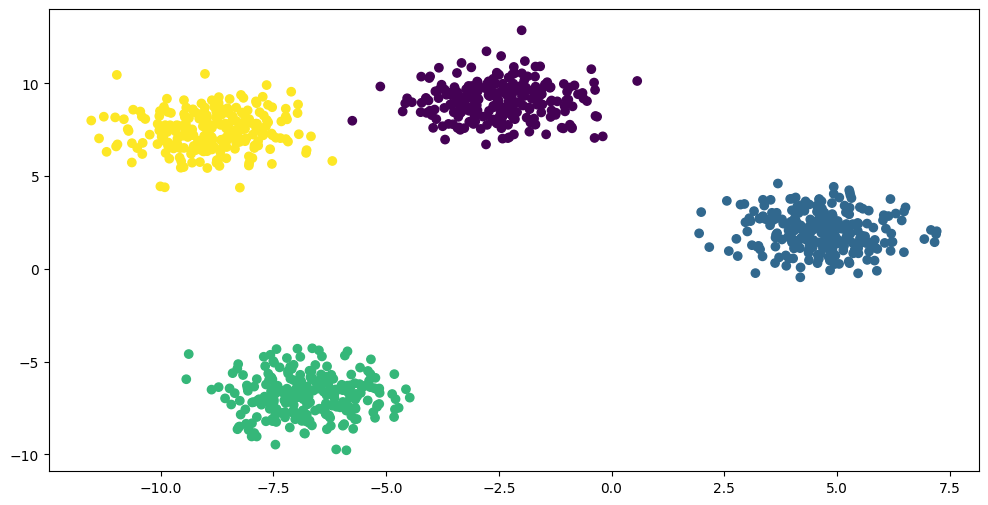

In [50]:
num_class=4
num_features=2
random_seed=42
x_blobs,y_blobs=make_blobs(n_samples=1000,n_features=num_features,centers=num_class,cluster_std=1,random_state=random_seed)
x_blobs_train,x_blobs_test,y_blobs_train,y_blobs_test=train_test_split(x_blobs,y_blobs,test_size=0.2,random_state=random_seed)
plt.figure(figsize=(12,6))
plt.scatter(x_blobs[:,0],x_blobs[:,1],c=y_blobs)


In [51]:
device='cuda' if torch.cuda.is_available() else 'cpu'
from torch import nn
class Blobmodel(nn.Module):
  def __init__(self,input_feauters:int,output_featers:int,hidden_layers:int=8):
    super().__init__()
    self.linear_layer_stick=(nn.Sequential(
        nn.Linear(in_features=input_feauters,out_features=hidden_layers),
        nn.ReLU(),
        nn.Linear(in_features=hidden_layers,out_features=hidden_layers),
        nn.ReLU(),
        nn.Linear(in_features=hidden_layers,out_features=output_featers)

    ))
  def forward(self,x:torch.tensor)->torch.tensor:
    return self.linear_layer_stick(x)
model_3= Blobmodel(input_feauters=num_features,output_featers=num_class).to(device)


In [52]:
loss_fn=nn.CrossEntropyLoss()
optomizier=torch.optim.SGD(params=model_3.parameters(),lr=0.1)

In [53]:
x_blobs_train=torch.from_numpy(x_blobs_train).float()
y_blobs_train=torch.from_numpy(y_blobs_train).type(torch.LongTensor)
x_blobs_test=torch.from_numpy(x_blobs_test).float()
y_blobs_test=torch.from_numpy(y_blobs_test).type(torch.LongTensor)

In [54]:
test_1=x_blobs_train.to(device)

In [55]:
x_blobs_train,y_blobs_train=x_blobs_train.to(device),y_blobs_train.to(device)
x_blobs_test,y_blobs_test=x_blobs_test.to(device),y_blobs_test.to(device)

In [56]:
logist=model_3(test_1[:5])

In [57]:
output_prop=torch.softmax(logist,dim=1)
output_prop

tensor([[0.3076, 0.3243, 0.1493, 0.2188],
        [0.3568, 0.1334, 0.1712, 0.3386],
        [0.3011, 0.1843, 0.2823, 0.2323],
        [0.3007, 0.1844, 0.2789, 0.2360],
        [0.3467, 0.1418, 0.1871, 0.3245]], grad_fn=<SoftmaxBackward0>)

In [58]:
outputs=torch.argmax(output_prop,dim=1)
outputs

tensor([1, 0, 0, 0, 0])

In [59]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)
epochs=100
for epoch in range(epochs):
  model_3.train()
  optomizier.zero_grad()
  train_logist=model_3(x_blobs_train)
  train_loss=loss_fn(train_logist,y_blobs_train)
  train_loss.backward()
  optomizier.step()

with torch.inference_mode():
  model_3.eval()
  test_logist=model_3(x_blobs_test)
  test_loss=loss_fn(test_logist,y_blobs_test)
  print(f'Epoch : {epoch}, Train Loss : {train_loss.item()}, Test Loss : { test_loss.item()}')

Epoch : 99, Train Loss : 0.010029212571680546, Test Loss : 0.00820151437073946


In [61]:
import requests
from pathlib import Path

url = "https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/helper_functions.py"

response = requests.get(url)
with open("helper_functions.py", "wb") as f:
    f.write(response.content)

from helper_functions import plot_decision_boundary

In [62]:
import matplotlib.pyplot as plt


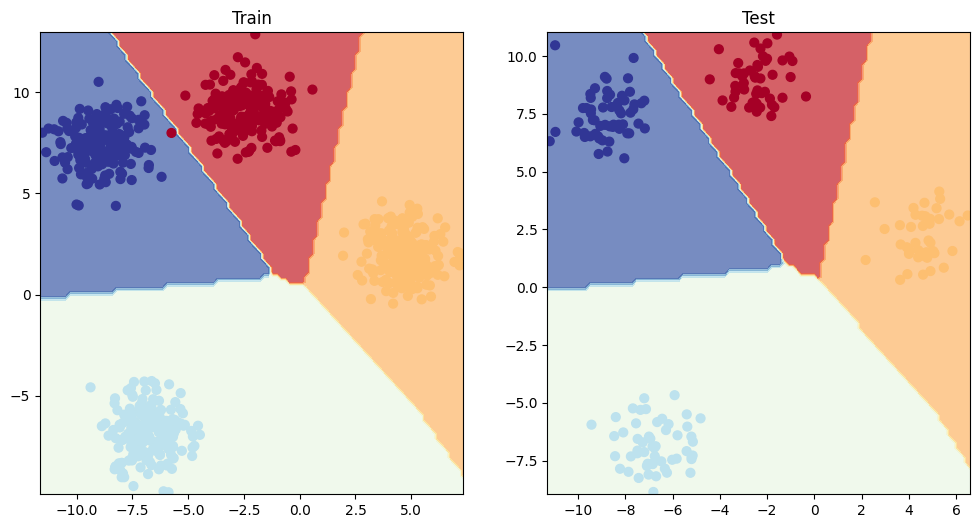

In [63]:
plt.figure(figsize=(12,6))
plt.subplot(1,2,1)
plt.title('Train')
plot_decision_boundary(model_3,x_blobs_train,y_blobs_train)
plt.subplot(1,2,2)
plt.title('Test')
plot_decision_boundary(model_3,x_blobs_test,y_blobs_test)